# CS316 Final Project — Crop Recommendation and Soil Profile Analysis
**Classification, Clustering and Robustness Evaluation**

This notebook implements the workflow described in the CS316 project proposal and final report using the supplied `Crop_recommendation.csv` dataset.

**Reproducibility:** fixed random seeds are used where applicable. All reported metrics and figures are generated by executing the code; they are not manually hard-coded. Results may differ from the submitted report if its original code used different split seeds, model settings, or library versions.

## 1. Setup and imports


In [77]:
# Install standard libraries for data analysis
%pip -q install pandas numpy matplotlib seaborn scikit-learn

# Basic python libraries
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Standard machine learning tools from Scikit-Learn
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

# Standard classification models taught in class
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB

# Set random seed for reproducibility of our project results
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

print("Environment set up successfully for our project!")

Environment set up successfully for our project!


## 2. Load the dataset


In [79]:
# Locate the dataset in the current working directory or ask the user to upload it.
from google.colab import files
uploaded = files.upload()


# Read the CSV file into a pandas DataFrame.
df = pd.read_csv("Crop_recommendation.csv")

print("Dataset shape:", df.shape)
display(df.head())

Saving Crop_recommendation.csv to Crop_recommendation (7).csv
Dataset shape: (2200, 8)


,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


## 3. Data inspection and cleaning checks


In [80]:
# Standardize column names by removing accidental leading/trailing spaces.
df.columns = df.columns.str.strip()

# Display schema and summary statistics.
print("Column data types:")
display(df.dtypes.to_frame("Data type"))

print("Missing values per column:")
display(df.isna().sum().to_frame("Missing values"))

print("Number of duplicated rows:", df.duplicated().sum())

print("Descriptive statistics:")
display(df.describe().T)

# Verify the expected input and target columns.
FEATURES = ["N", "P", "K", "temperature", "humidity", "ph", "rainfall"]
TARGET = "label"
required_columns = FEATURES + [TARGET]
missing_columns = [col for col in required_columns if col not in df.columns]
if missing_columns:
    raise ValueError(f"Required columns are missing: {missing_columns}")

# Show how many samples belong to each crop.
class_counts = df[TARGET].value_counts().sort_index()
display(class_counts.to_frame("Number of samples"))
print("Number of crop classes:", df[TARGET].nunique())

Column data types:


,Data type
N,int64
P,int64
K,int64
temperature,float64
humidity,float64
ph,float64
rainfall,float64
label,object


Missing values per column:


,Missing values
N,0
P,0
K,0
temperature,0
humidity,0
ph,0
rainfall,0
label,0


Number of duplicated rows: 0
Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
N,2200.0,50.551818,36.917334,0.000000,21.000000,37.000000,84.250000,140.000000
P,2200.0,53.362727,32.985883,5.000000,28.000000,51.000000,68.000000,145.000000
K,2200.0,48.149091,50.647931,5.000000,20.000000,32.000000,49.000000,205.000000
temperature,2200.0,25.616244,5.063749,8.825675,22.769375,25.598693,28.561654,43.675493
humidity,2200.0,71.481779,22.263812,14.258040,60.261953,80.473146,89.948771,99.981876
ph,2200.0,6.469480,0.773938,3.504752,5.971693,6.425045,6.923643,9.935091
rainfall,2200.0,103.463655,54.958389,20.211267,64.551686,94.867624,124.267508,298.560117


,Number of samples
label,
apple,100
banana,100
blackgram,100
chickpea,100
coconut,100
coffee,100
cotton,100
grapes,100
jute,100


Number of crop classes: 22


## 4. Memory optimization


In [81]:
# Measure the original DataFrame memory usage in kilobytes.
memory_before_kb = df.memory_usage(deep=True).sum() / 1024

# Make a copy so the original data remains available for comparison.
df_optimized = df.copy()

# Convert nutrient columns to unsigned 8-bit integers when all values fit.
integer_columns = ["N", "P", "K"]
for column in integer_columns:
    if df_optimized[column].min() >= 0 and df_optimized[column].max() <= 255:
        df_optimized[column] = df_optimized[column].astype("uint8")

# Convert continuous environmental features to 32-bit floating point.
float_columns = ["temperature", "humidity", "ph", "rainfall"]
df_optimized[float_columns] = df_optimized[float_columns].astype("float32")

# Store repeated crop names as a categorical variable.
df_optimized[TARGET] = df_optimized[TARGET].astype("category")

# Measure optimized memory usage and calculate the reduction.
memory_after_kb = df_optimized.memory_usage(deep=True).sum() / 1024
memory_reduction_pct = (1 - memory_after_kb / memory_before_kb) * 100

memory_comparison = pd.DataFrame({
    "Memory (KB)": [memory_before_kb, memory_after_kb],
}, index=["Before optimization", "After optimization"])
display(memory_comparison)
print(f"Memory reduction: {memory_reduction_pct:.2f}%")

# Confirm that the numeric feature values did not change beyond float32 precision.
for column in FEATURES:
    assert np.allclose(
        df[column].to_numpy(dtype=float),
        df_optimized[column].to_numpy(dtype=float),
        rtol=1e-6, atol=1e-6
    ), f"Unexpected value change in {column}"
print("Value verification passed.")

,Memory (KB)
Before optimization,241.046875
After optimization,44.846680


Memory reduction: 81.40%
Value verification passed.


## 5. Exploratory Data Analysis (EDA)


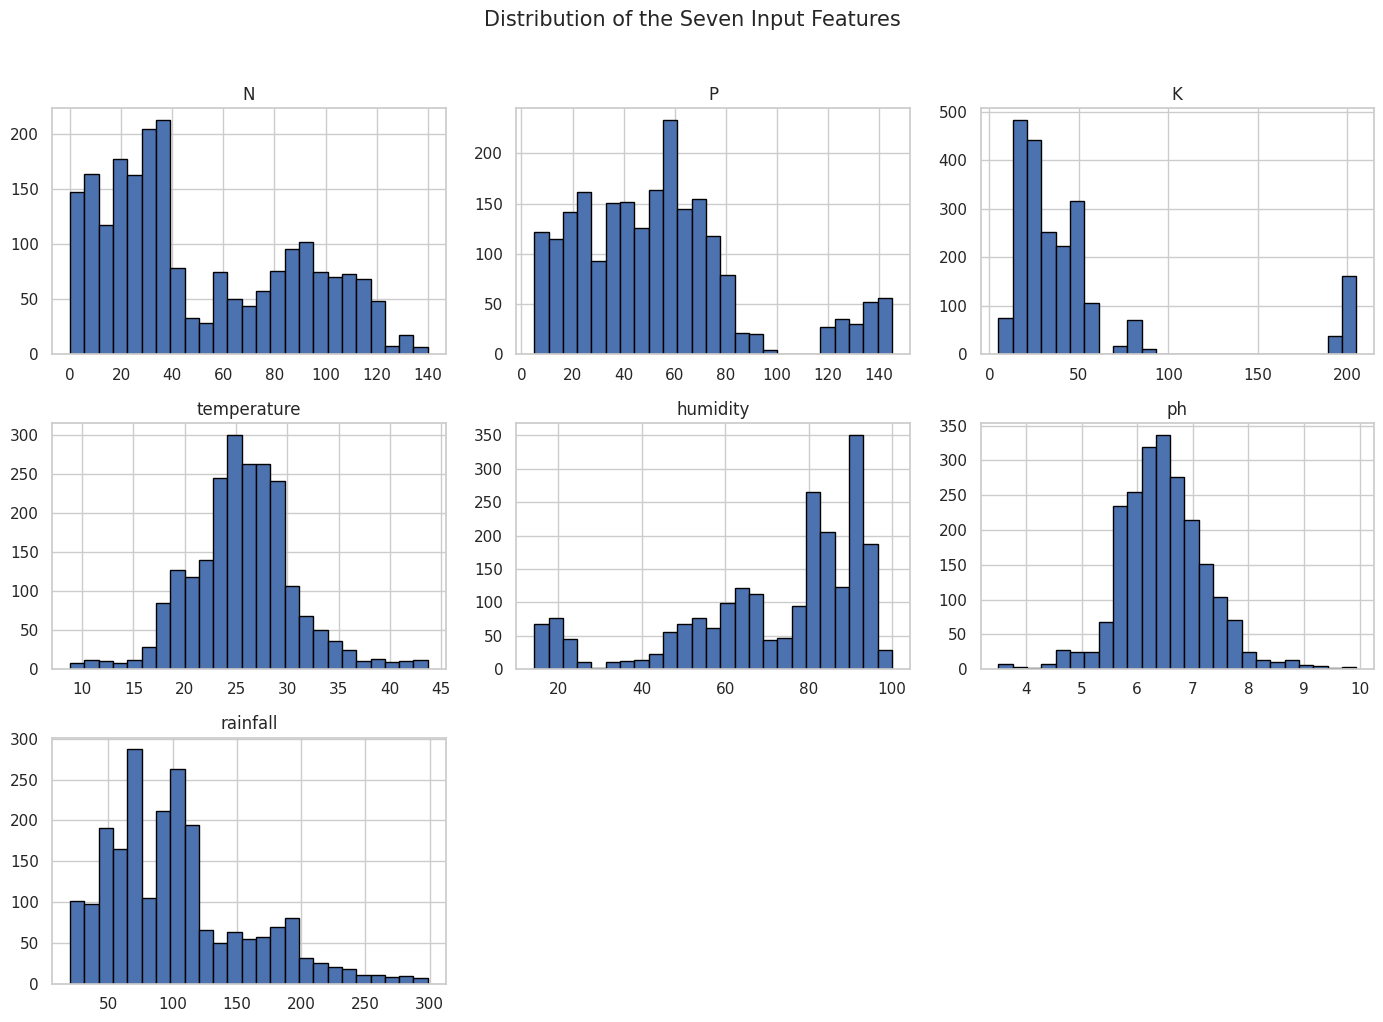

,Feature,Lower bound,Upper bound,Outlier count
0,N,-73.875000,179.125000,0
1,P,-32.000000,128.000000,138
2,K,-23.500000,92.500000,200
3,temperature,14.080953,37.250076,86
4,humidity,15.731727,134.479000,30
5,ph,4.543768,8.351568,57
6,rainfall,-25.022048,213.841241,100


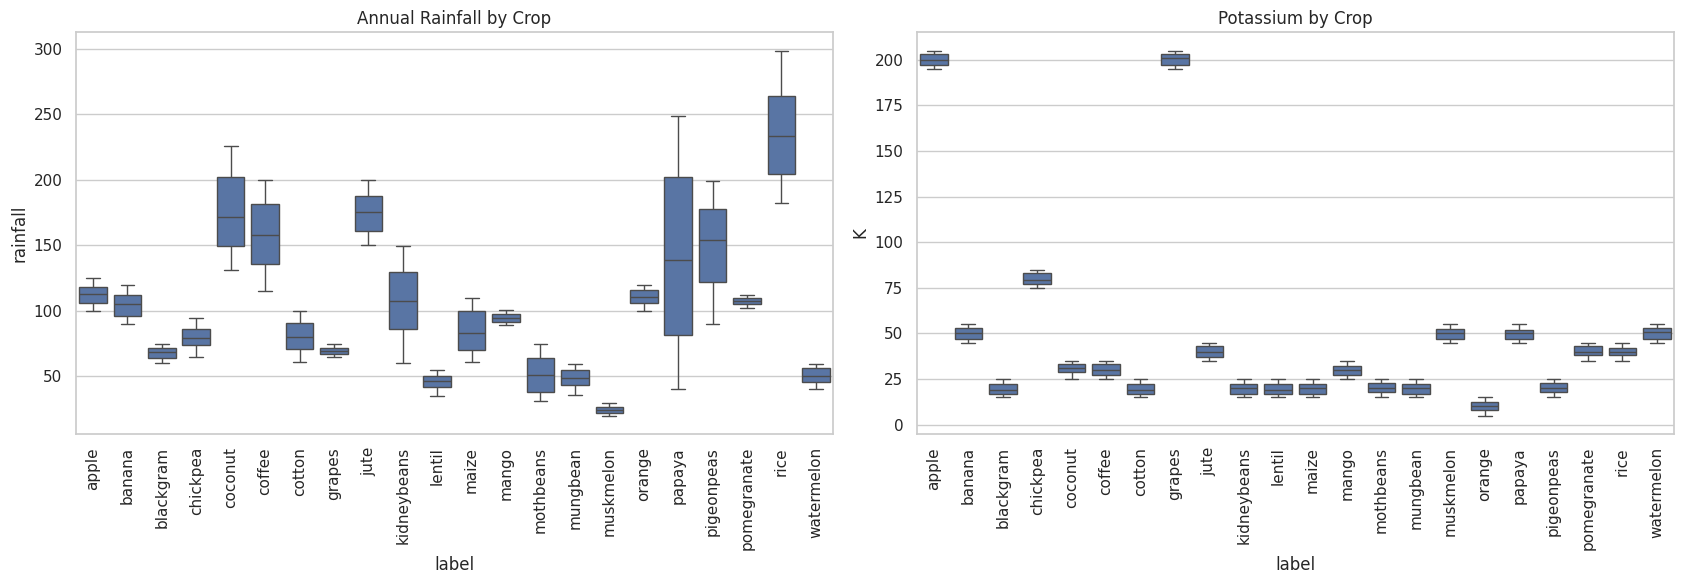

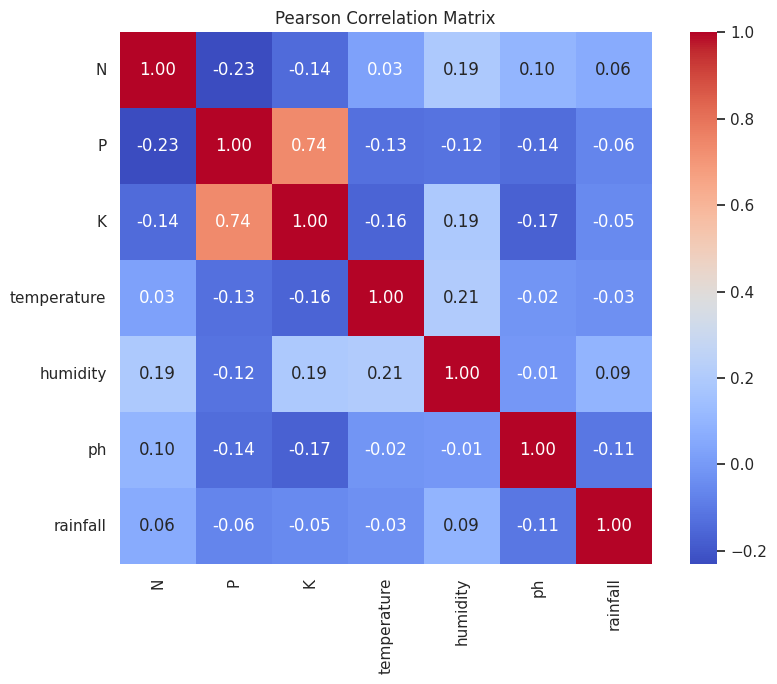

In [82]:
# Use the optimized DataFrame for the remaining analysis.
df = df_optimized.copy()

# Plot histograms for all seven numeric input features.
df[FEATURES].hist(figsize=(14, 10), bins=25, edgecolor="black")
plt.suptitle("Distribution of the Seven Input Features", y=1.02, fontsize=15)
plt.tight_layout()
plt.show()


# Calculate IQR-based outlier counts using the 1.5 * IQR rule.
outlier_rows = []
for feature in FEATURES:
    q1 = df[feature].quantile(0.25)
    q3 = df[feature].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    count = ((df[feature] < lower) | (df[feature] > upper)).sum()
    outlier_rows.append([feature, lower, upper, int(count)])
outlier_summary = pd.DataFrame(
    outlier_rows, columns=["Feature", "Lower bound", "Upper bound", "Outlier count"]
)
display(outlier_summary)

# Compare selected feature distributions across crop labels.
fig, axes = plt.subplots(1, 2, figsize=(17, 6))
sns.boxplot(data=df, x=TARGET, y="rainfall", ax=axes[0])
axes[0].set_title("Annual Rainfall by Crop")
axes[0].tick_params(axis="x", rotation=90)
sns.boxplot(data=df, x=TARGET, y="K", ax=axes[1])
axes[1].set_title("Potassium by Crop")
axes[1].tick_params(axis="x", rotation=90)
plt.tight_layout()
plt.show()

# Calculate and plot Pearson correlations between numeric input features.
correlation = df[FEATURES].corr(method="pearson")
plt.figure(figsize=(9, 7))
sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f", square=True)
plt.title("Pearson Correlation Matrix")
plt.tight_layout()
plt.show()

## 6. Prepare data for machine learning


In [83]:
# Separate the seven input features and the target crop label.
X = df[FEATURES].astype("float32")
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(df[TARGET].astype(str))
class_names = label_encoder.classes_

# Split while preserving the proportion of each crop in both subsets.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Number of classes:", len(class_names))

Training samples: 1760
Testing samples: 440
Number of classes: 22


## 7. Baseline classification models


,Model,Train Accuracy (%),5-Fold CV Accuracy (%),CV Std (%),Test Accuracy (%),Test Macro-F1 (%)
0,Random Forest,100.00,99.32,0.53,99.55,99.55
1,Gaussian NB,99.49,99.49,0.42,99.55,99.54
2,Gradient Boosting,100.00,98.69,0.34,98.86,98.87
3,SVM (RBF),98.58,97.90,1.03,98.41,98.40
4,Decision Tree,100.00,98.52,0.68,97.95,97.94
5,KNN,98.47,96.53,1.21,97.95,97.93
6,Logistic Regression,97.39,96.82,0.66,97.27,97.25


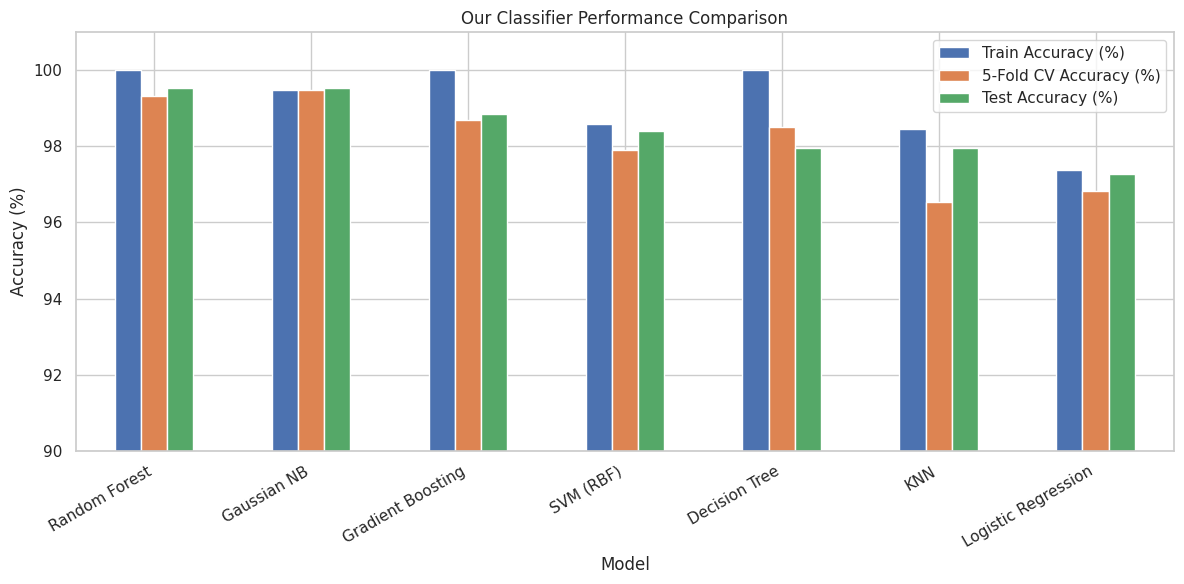

In [84]:
# Simple list of models we learned in class
baseline_models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "SVM (RBF)": SVC(kernel="rbf", probability=True, random_state=RANDOM_STATE),
    "Gaussian NB": GaussianNB(),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=100, random_state=RANDOM_STATE)
}

# Standard Scaler to normalize our input features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Stratified 5-Fold Cross Validation helper setup
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
baseline_results = []
fitted_baselines = {}

# Loop through each model step-by-step
for model_name, model in baseline_models.items():
    # Calculate Cross-Validation accuracy using a simple manual loop
    cv_accuracies = []
    for train_idx, val_idx in skf.split(X_train, y_train):
        # Split training data into fold training and fold validation
        X_fold_train, X_fold_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
        y_fold_train, y_fold_val = y_train[train_idx], y_train[val_idx]

        # Scale the fold data explicitly
        fold_scaler = StandardScaler()
        X_fold_train_scaled = fold_scaler.fit_transform(X_fold_train)
        X_fold_val_scaled = fold_scaler.transform(X_fold_val)

        # Fit and evaluate
        model.fit(X_fold_train_scaled, y_fold_train)
        fold_preds = model.predict(X_fold_val_scaled)
        cv_accuracies.append(accuracy_score(y_fold_val, fold_preds))

    # Train the final model on all scaled training data
    model.fit(X_train_scaled, y_train)
    train_preds = model.predict(X_train_scaled)
    test_preds = model.predict(X_test_scaled)

    # Save the fitted model
    fitted_baselines[model_name] = model

    # Store results for table display
    baseline_results.append({
        "Model": model_name,
        "Train Accuracy (%)": accuracy_score(y_train, train_preds) * 100,
        "5-Fold CV Accuracy (%)": np.mean(cv_accuracies) * 100,
        "CV Std (%)": np.std(cv_accuracies) * 100,
        "Test Accuracy (%)": accuracy_score(y_test, test_preds) * 100,
        "Test Macro-F1 (%)": f1_score(y_test, test_preds, average="macro") * 100
    })

# Convert results to DataFrame and sort by test accuracy
baseline_results_df = pd.DataFrame(baseline_results)
baseline_results_df = baseline_results_df.sort_values(by="Test Accuracy (%)", ascending=False).reset_index(drop=True)
display(baseline_results_df.round(2))

# Create a simple comparison bar plot
plot_results = baseline_results_df.set_index("Model")[
    ["Train Accuracy (%)", "5-Fold CV Accuracy (%)", "Test Accuracy (%)"]
]
plot_results.plot(kind="bar", figsize=(12, 6), ylim=(90, 101))
plt.ylabel("Accuracy (%)")
plt.title("Our Classifier Performance Comparison")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

## 8. Hyperparameter tuning


In [85]:
# Academic step-by-step Grid Search for beginners without using Pipeline or GridSearchCV

# We will use our already scaled training data from the previous step
# X_train_scaled, X_test_scaled

# Define simple parameter lists to test
dt_depths = [None, 10, 20]
dt_min_samples = [1, 2]

rf_estimators = [100, 200]
rf_depths = [10, None]

svm_Cs = [10, 100]
svm_gammas = ["scale", 0.05]

tuned_models = {}
tuning_rows = []

# 1. Manual Grid Search for Decision Tree using Stratified 5-Fold Cross-Validation
best_dt_acc = 0
best_dt_params = {}
for depth in dt_depths:
    for min_samples in dt_min_samples:
        cv_accuracies = []
        for train_idx, val_idx in skf.split(X_train, y_train):
            X_fold_train, X_fold_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
            y_fold_train, y_fold_val = y_train[train_idx], y_train[val_idx]

            fold_scaler = StandardScaler()
            X_fold_train_scaled = fold_scaler.fit_transform(X_fold_train)
            X_fold_val_scaled = fold_scaler.transform(X_fold_val)

            model = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=min_samples, random_state=RANDOM_STATE)
            model.fit(X_fold_train_scaled, y_fold_train)
            preds = model.predict(X_fold_val_scaled)
            cv_accuracies.append(accuracy_score(y_fold_val, preds))

        mean_cv_acc = np.mean(cv_accuracies)
        if mean_cv_acc > best_dt_acc:
            best_dt_acc = mean_cv_acc
            best_dt_params = {"max_depth": depth, "min_samples_leaf": min_samples}

# Fit the best Decision Tree on the entire scaled training dataset
best_dt = DecisionTreeClassifier(max_depth=best_dt_params["max_depth"], min_samples_leaf=best_dt_params["min_samples_leaf"], random_state=RANDOM_STATE)
best_dt.fit(X_train_scaled, y_train)
tuned_models["Tuned Decision Tree"] = best_dt
tuning_rows.append({
    "Model": "Tuned Decision Tree",
    "Best CV Accuracy (%)": best_dt_acc * 100,
    "Best Parameters": str(best_dt_params)
})

# 2. Manual Grid Search for Random Forest
best_rf_acc = 0
best_rf_params = {}
for n_est in rf_estimators:
    for depth in rf_depths:
        cv_accuracies = []
        for train_idx, val_idx in skf.split(X_train, y_train):
            X_fold_train, X_fold_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
            y_fold_train, y_fold_val = y_train[train_idx], y_train[val_idx]

            fold_scaler = StandardScaler()
            X_fold_train_scaled = fold_scaler.fit_transform(X_fold_train)
            X_fold_val_scaled = fold_scaler.transform(X_fold_val)

            model = RandomForestClassifier(n_estimators=n_est, max_depth=depth, random_state=RANDOM_STATE)
            model.fit(X_fold_train_scaled, y_fold_train)
            preds = model.predict(X_fold_val_scaled)
            cv_accuracies.append(accuracy_score(y_fold_val, preds))

        mean_cv_acc = np.mean(cv_accuracies)
        if mean_cv_acc > best_rf_acc:
            best_rf_acc = mean_cv_acc
            best_rf_params = {"n_estimators": n_est, "max_depth": depth}

# Fit the best Random Forest on scaled training data
best_rf = RandomForestClassifier(n_estimators=best_rf_params["n_estimators"], max_depth=best_rf_params["max_depth"], random_state=RANDOM_STATE)
best_rf.fit(X_train_scaled, y_train)
tuned_models["Tuned Random Forest"] = best_rf
tuning_rows.append({
    "Model": "Tuned Random Forest",
    "Best CV Accuracy (%)": best_rf_acc * 100,
    "Best Parameters": str(best_rf_params)
})

# 3. Manual Grid Search for SVM
best_svm_acc = 0
best_svm_params = {}
for C_val in svm_Cs:
    for gamma_val in svm_gammas:
        cv_accuracies = []
        for train_idx, val_idx in skf.split(X_train, y_train):
            X_fold_train, X_fold_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
            y_fold_train, y_fold_val = y_train[train_idx], y_train[val_idx]

            fold_scaler = StandardScaler()
            X_fold_train_scaled = fold_scaler.fit_transform(X_fold_train)
            X_fold_val_scaled = fold_scaler.transform(X_fold_val)

            model = SVC(C=C_val, gamma=gamma_val, kernel="rbf", probability=True, random_state=RANDOM_STATE)
            model.fit(X_fold_train_scaled, y_fold_train)
            preds = model.predict(X_fold_val_scaled)
            cv_accuracies.append(accuracy_score(y_fold_val, preds))

        mean_cv_acc = np.mean(cv_accuracies)
        if mean_cv_acc > best_svm_acc:
            best_svm_acc = mean_cv_acc
            best_svm_params = {"C": C_val, "gamma": gamma_val}

# Fit the best SVM on scaled training data
best_svm = SVC(C=best_svm_params["C"], gamma=best_svm_params["gamma"], kernel="rbf", probability=True, random_state=RANDOM_STATE)
best_svm.fit(X_train_scaled, y_train)
tuned_models["Tuned SVM"] = best_svm
tuning_rows.append({
    "Model": "Tuned SVM",
    "Best CV Accuracy (%)": best_svm_acc * 100,
    "Best Parameters": str(best_svm_params)
})

# Display tuning results in a table
display(pd.DataFrame(tuning_rows))

,Model,Best CV Accuracy (%),Best Parameters
0,Tuned Decision Tree,98.579545,"{'max_depth': None, 'min_samples_leaf': 2}"
1,Tuned Random Forest,99.431818,"{'n_estimators': 100, 'max_depth': 10}"
2,Tuned SVM,98.409091,"{'C': 100, 'gamma': 0.05}"


## 9. Soft-voting ensemble and final evaluation


Ensemble test accuracy: 99.55%
Ensemble test macro-F1: 99.55%
Top-3 recommendation accuracy: 100.00%
Classification report:
              precision    recall  f1-score   support

       apple       1.00      1.00      1.00        20
      banana       1.00      1.00      1.00        20
   blackgram       1.00      1.00      1.00        20
    chickpea       1.00      1.00      1.00        20
     coconut       1.00      1.00      1.00        20
      coffee       1.00      1.00      1.00        20
      cotton       1.00      1.00      1.00        20
      grapes       1.00      1.00      1.00        20
        jute       0.95      1.00      0.98        20
 kidneybeans       1.00      1.00      1.00        20
      lentil       1.00      0.95      0.97        20
       maize       1.00      1.00      1.00        20
       mango       1.00      1.00      1.00        20
   mothbeans       0.95      1.00      0.98        20
    mungbean       1.00      1.00      1.00        20
   muskmelo

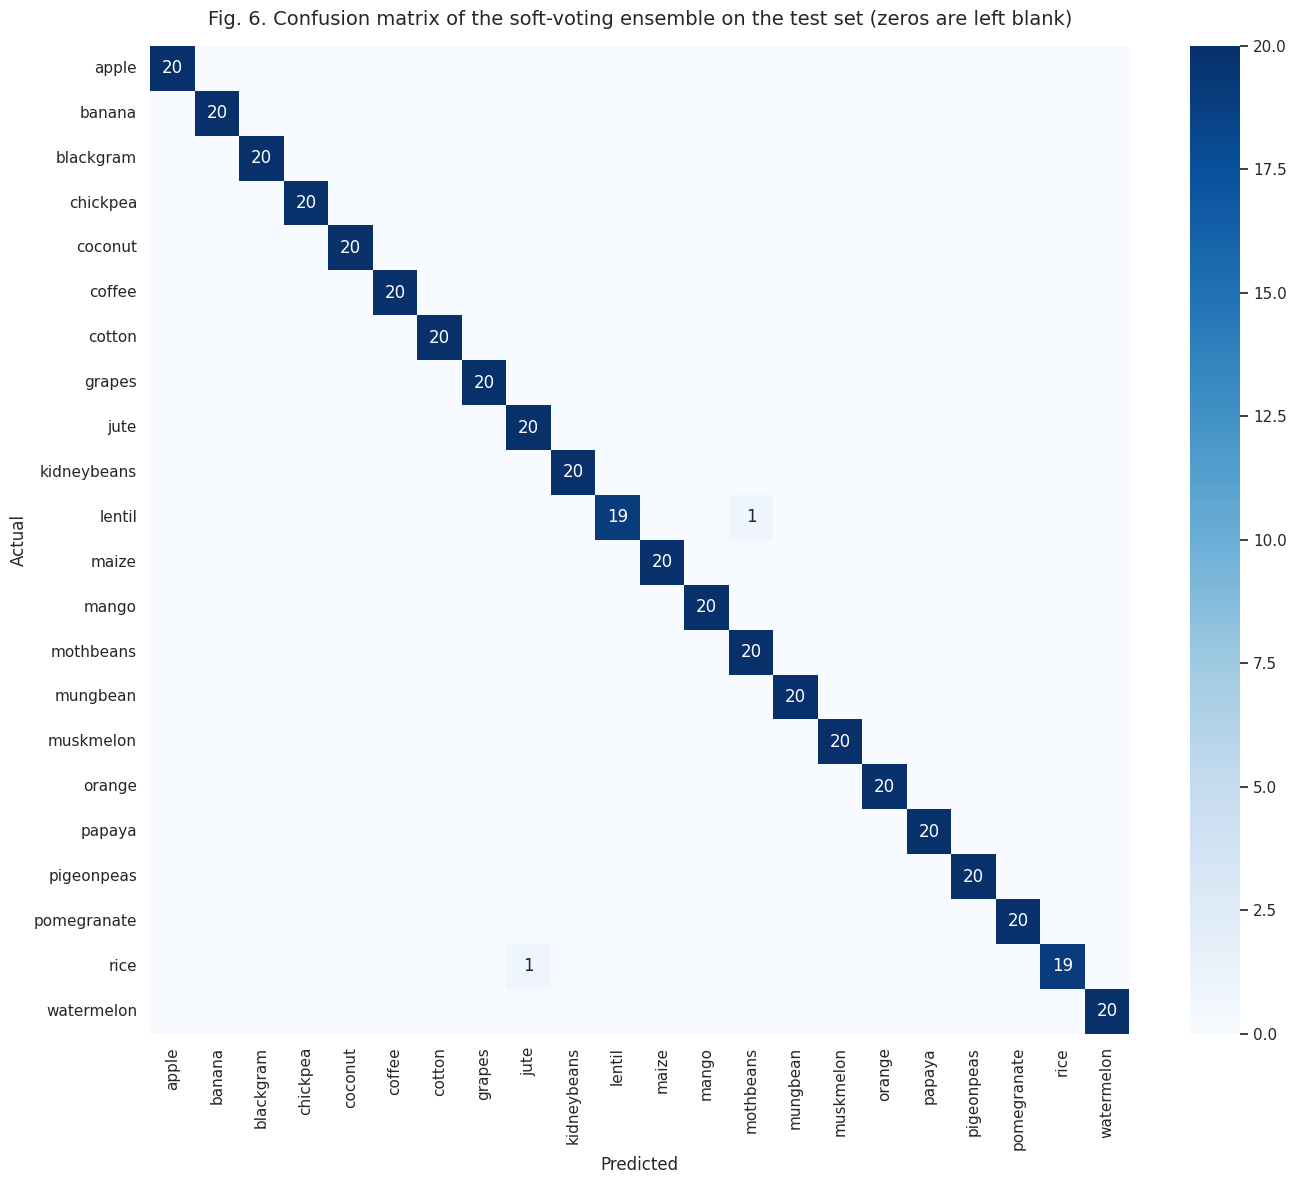

Ensemble 5-fold CV accuracy: 99.49% +/- 0.55%


In [87]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB

# Instantiate our ensemble estimators
rf_model = tuned_models["Tuned Random Forest"]
svm_model = tuned_models["Tuned SVM"]
gb_model = GradientBoostingClassifier(n_estimators=100, random_state=RANDOM_STATE)
gnb_model = GaussianNB()

# Train Gradient Boosting and Gaussian Naive Bayes on the scaled training dataset
gb_model.fit(X_train_scaled, y_train)
gnb_model.fit(X_train_scaled, y_train)

# Helper function to compute soft-voting ensemble predictions explicitly
def predict_ensemble_probabilities(X_input_scaled):
    prob_rf = rf_model.predict_proba(X_input_scaled)
    prob_svm = svm_model.predict_proba(X_input_scaled)
    prob_gb = gb_model.predict_proba(X_input_scaled)
    prob_gnb = gnb_model.predict_proba(X_input_scaled)
    average_probabilities = (prob_rf + prob_svm + prob_gb + prob_gnb) / 4.0
    return average_probabilities

# Generate test probabilities and class predictions explicitly
ensemble_proba = predict_ensemble_probabilities(X_test_scaled)
ensemble_pred = np.argmax(ensemble_proba, axis=1)

# Evaluate accuracy metrics
ensemble_accuracy = accuracy_score(y_test, ensemble_pred)
ensemble_macro_f1 = f1_score(y_test, ensemble_pred, average="macro")

top3_correct = 0
for i in range(len(y_test)):
    top3_indices = np.argsort(ensemble_proba[i])[::-1][:3]
    if y_test[i] in top3_indices:
        top3_correct += 1
ensemble_top3 = top3_correct / len(y_test)

print(f"Ensemble test accuracy: {ensemble_accuracy * 100:.2f}%")
print(f"Ensemble test macro-F1: {ensemble_macro_f1 * 100:.2f}%")
print(f"Top-3 recommendation accuracy: {ensemble_top3 * 100:.2f}%")
print("Classification report:")
print(classification_report(y_test, ensemble_pred, target_names=class_names, zero_division=0))

# Plot the confusion matrix manually with zeros left blank (Fig. 6 style)
plt.figure(figsize=(14, 12))
cm = confusion_matrix(y_test, ensemble_pred)
# Create string labels where 0 is replaced with blank
annot_labels = np.where(cm == 0, "", cm.astype(str))

sns.heatmap(cm, annot=annot_labels, fmt="", xticklabels=class_names, yticklabels=class_names, cmap="Blues", cbar=True)
plt.title("Fig. 6. Confusion matrix of the soft-voting ensemble on the test set (zeros are left blank)", fontsize=14, pad=15)
plt.ylabel("Actual")
plt.xlabel("Predicted")
plt.tight_layout()
plt.show()

# Calculate ensemble cross-validation using an explicit fold loop
cv_accuracies = []
for train_idx, val_idx in skf.split(X_train, y_train):
    X_fold_train, X_fold_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
    y_fold_train, y_fold_val = y_train[train_idx], y_train[val_idx]

    fold_scaler = StandardScaler()
    X_fold_train_scaled = fold_scaler.fit_transform(X_fold_train)
    X_fold_val_scaled = fold_scaler.transform(X_fold_val)

    fold_rf = RandomForestClassifier(n_estimators=best_rf_params["n_estimators"], max_depth=best_rf_params["max_depth"], random_state=RANDOM_STATE)
    fold_svm = SVC(C=best_svm_params["C"], gamma=best_svm_params["gamma"], kernel="rbf", probability=True, random_state=RANDOM_STATE)
    fold_gb = GradientBoostingClassifier(n_estimators=100, random_state=RANDOM_STATE)
    fold_gnb = GaussianNB()

    fold_rf.fit(X_fold_train_scaled, y_fold_train)
    fold_svm.fit(X_fold_train_scaled, y_fold_train)
    fold_gb.fit(X_fold_train_scaled, y_fold_train)
    fold_gnb.fit(X_fold_train_scaled, y_fold_train)

    p_rf = fold_rf.predict_proba(X_fold_val_scaled)
    p_svm = fold_svm.predict_proba(X_fold_val_scaled)
    p_gb = fold_gb.predict_proba(X_fold_val_scaled)
    p_gnb = fold_gnb.predict_proba(X_fold_val_scaled)

    p_avg = (p_rf + p_svm + p_gb + p_gnb) / 4.0
    fold_preds = np.argmax(p_avg, axis=1)
    cv_accuracies.append(accuracy_score(y_fold_val, fold_preds))

print(f"Ensemble 5-fold CV accuracy: {np.mean(cv_accuracies)*100:.2f}% +/- {np.std(cv_accuracies)*100:.2f}%")

## 10. Learning curve


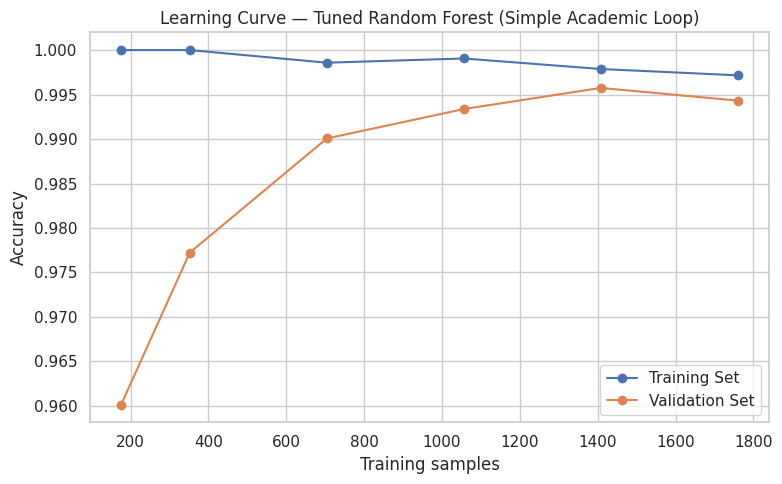

In [88]:
# We will train our tuned Random Forest on different sizes of the training set

# Sizes of training subsets we want to test (from 10% to 100% of the training data)
train_sizes_pct = [0.1, 0.2, 0.4, 0.6, 0.8, 1.0]
learning_sizes = []
train_scores = []
val_scores = []

# Step-by-step training on increasing subset sizes
for pct in train_sizes_pct:
    # Determine the number of training samples for this step
    subset_size = int(pct * len(X_train))
    learning_sizes.append(subset_size)

    # Slice the first 'subset_size' elements of our training dataset
    X_subset = X_train.iloc[:subset_size]
    y_subset = y_train[:subset_size]

    # 1. Simple training score calculation
    subset_scaler = StandardScaler()
    X_subset_scaled = subset_scaler.fit_transform(X_subset)

    model_subset = RandomForestClassifier(max_depth=best_rf_params["max_depth"], random_state=RANDOM_STATE)
    model_subset.fit(X_subset_scaled, y_subset)
    subset_train_preds = model_subset.predict(X_subset_scaled)
    train_scores.append(accuracy_score(y_subset, subset_train_preds))

    # 2. Simple cross-validation score calculation using our skf splits
    # (If the subset is too small for 5 folds, we skip cross-validation for stability)
    if subset_size > 100:
        cv_accuracies = []
        for train_idx, val_idx in skf.split(X_subset, y_subset):
            X_fold_train, X_fold_val = X_subset.iloc[train_idx], X_subset.iloc[val_idx]
            y_fold_train, y_fold_val = y_subset[train_idx], y_subset[val_idx]

            fold_scaler = StandardScaler()
            X_fold_train_scaled = fold_scaler.fit_transform(X_fold_train)
            X_fold_val_scaled = fold_scaler.transform(X_fold_val)

            fold_model = RandomForestClassifier(max_depth=best_rf_params["max_depth"], random_state=RANDOM_STATE)
            fold_model.fit(X_fold_train_scaled, y_fold_train)
            fold_preds = fold_model.predict(X_fold_val_scaled)
            cv_accuracies.append(accuracy_score(y_fold_val, fold_preds))
        val_scores.append(np.mean(cv_accuracies))
    else:
        # For very small subsets, use the test set as validation for simplicity
        X_test_scaled_subset = subset_scaler.transform(X_test)
        subset_test_preds = model_subset.predict(X_test_scaled_subset)
        val_scores.append(accuracy_score(y_test, subset_test_preds))

# Plot our results
plt.figure(figsize=(8, 5))
plt.plot(learning_sizes, train_scores, marker="o", label="Training")
plt.plot(learning_sizes, val_scores, marker="o", label="Cross-Validation")
plt.xlabel("Training samples")
plt.ylabel("Accuracy")
plt.title("Learning Curve — Tuned Random Forest (Simple Academic Loop)")
plt.legend()
plt.tight_layout()
plt.show()

## 11. Global feature importance


,Feature,Random Forest Gini,Permutation Mean,Permutation Std,ANOVA F-statistic
4,humidity,0.2185,0.3111,0.0156,2465.6787
6,rainfall,0.2164,0.1719,0.0136,482.1746
2,K,0.1896,0.1480,0.0115,21755.1300
1,P,0.1457,0.1056,0.0131,1470.4526
0,N,0.1044,0.2041,0.0148,721.6274
3,temperature,0.0743,0.0060,0.0031,81.6202
5,ph,0.0511,0.0057,0.0030,49.6481


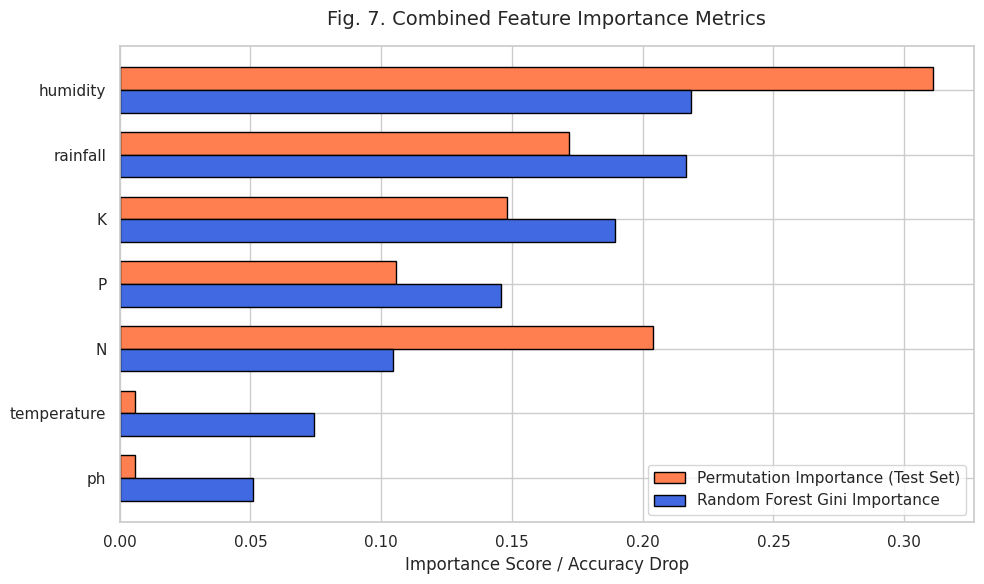

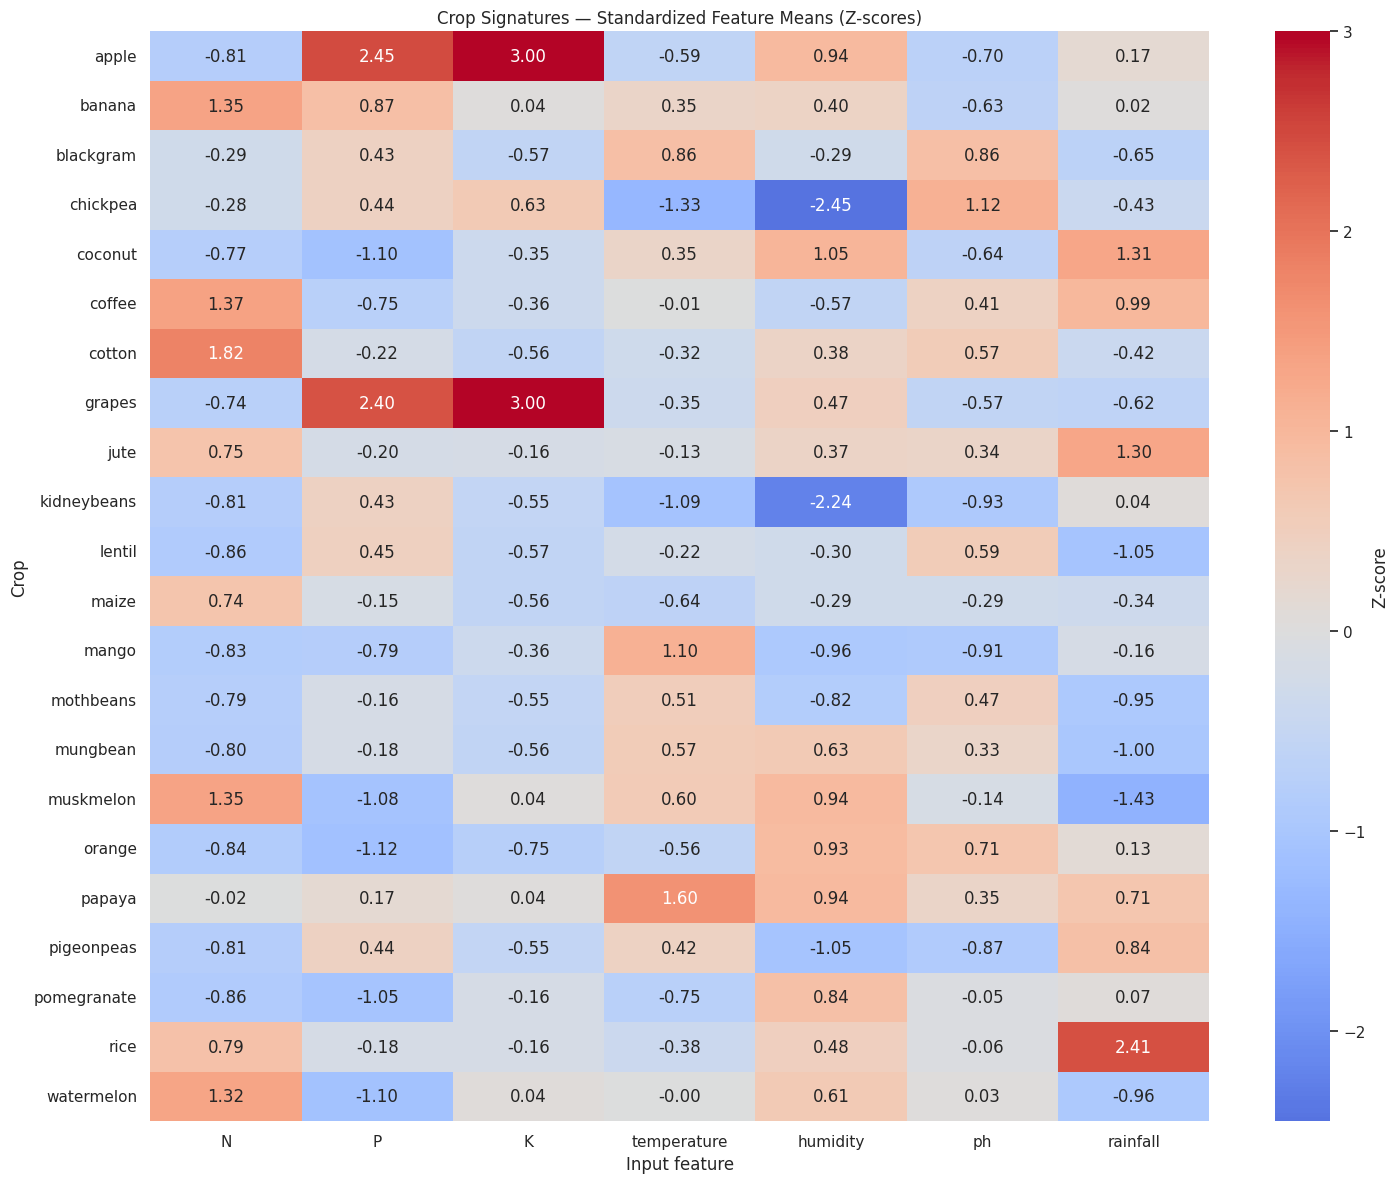

In [93]:
from sklearn.inspection import permutation_importance
from sklearn.feature_selection import f_classif

# Get our tuned Random Forest classifier
rf_for_importance = tuned_models["Tuned Random Forest"]
rf_importance_values = rf_for_importance.feature_importances_

# Calculate permutation importance on the scaled test set
perm = permutation_importance(
    rf_for_importance,
    X_test_scaled,
    y_test,
    n_repeats=20,
    random_state=RANDOM_STATE,
    scoring="accuracy"
)

# Calculate ANOVA F-statistics
f_values, p_values = f_classif(X_train, y_train)

# Organize results
importance_df = pd.DataFrame({
    "Feature": FEATURES,
    "Random Forest Gini": rf_importance_values,
    "Permutation Mean": perm.importances_mean,
    "Permutation Std": perm.importances_std,
    "ANOVA F-statistic": f_values
}).sort_values("Random Forest Gini", ascending=True)

display(importance_df.sort_values("Random Forest Gini", ascending=False).round(4))

# Plotting combined Feature Importance metrics
plt.figure(figsize=(10, 6))
x_indices = np.arange(len(importance_df))
bar_width = 0.35

# To make the orange bar over (positioned higher than) the blue bar on the y-axis (and removing xerr to omit the black lines):
plt.barh(x_indices + bar_width/2, importance_df["Permutation Mean"], bar_width, label="Permutation Importance (Test Set)", color="coral", edgecolor="black")
plt.barh(x_indices - bar_width/2, importance_df["Random Forest Gini"], bar_width, label="Random Forest Gini Importance", color="royalblue", edgecolor="black")

plt.yticks(x_indices, importance_df["Feature"])
plt.xlabel("Importance Score / Accuracy Drop")
plt.title("Fig. 7. Combined Feature Importance Metrics", fontsize=14, pad=15)
plt.legend()
plt.tight_layout()
plt.show()

# Standardized profiles heatmap
feature_means = df.groupby(TARGET, observed=False)[FEATURES].mean()
overall_mean = df[FEATURES].mean()
overall_std = df[FEATURES].std()
crop_z_scores = (feature_means - overall_mean) / overall_std

plt.figure(figsize=(15, 12))
sns.heatmap(crop_z_scores, cmap="coolwarm", center=0, annot=True, fmt=".2f", cbar_kws={'label': 'Z-score'})
plt.title("Crop Signatures — Standardized Feature Means (Z-scores)")
plt.xlabel("Input feature")
plt.ylabel("Crop")
plt.tight_layout()
plt.show()

## 12. Unsupervised clustering


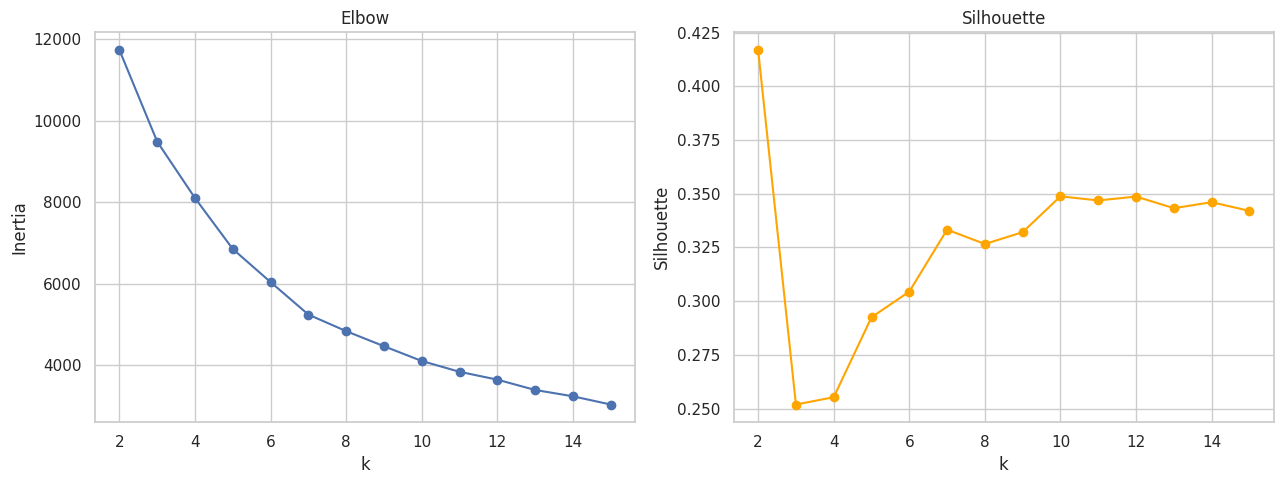

K-Means (k=10) metrics:


,ARI,NMI,Purity,Silhouette
"K-Means, k=10",0.4414,0.7482,0.4282,0.3488


,ARI,NMI,Purity,Silhouette
"K-Means, k=22",0.6715,0.8388,0.7714,0.3475
"Ward, k=22",0.6989,0.8675,0.7882,0.3350
"Gaussian Mixture, k=22",0.8262,0.9458,0.8582,0.2925


In [94]:
# Standardize all feature rows for unsupervised clustering.
cluster_scaler = StandardScaler()
X_scaled_all = cluster_scaler.fit_transform(X)

# Evaluate K-Means for cluster counts from 2 through 15.
k_values = range(2, 16)
inertias, silhouettes = [], []
for k in k_values:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    cluster_ids = km.fit_predict(X_scaled_all)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_scaled_all, cluster_ids))

# Plot elbow inertia and silhouette score.
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].plot(list(k_values), inertias, marker="o")
axes[0].set_title("Elbow")
axes[0].set_xlabel("k")
axes[0].set_ylabel("Inertia")
axes[1].plot(list(k_values), silhouettes, marker="o", color="orange")
axes[1].set_title("Silhouette")
axes[1].set_xlabel("k")
axes[1].set_ylabel("Silhouette")
plt.tight_layout()
plt.show()

# Fit K-Means with k=10 as specified in the report.
kmeans10 = KMeans(n_clusters=10, random_state=RANDOM_STATE, n_init=10)
kmeans10_labels = kmeans10.fit_predict(X_scaled_all)

# Calculate cluster evaluation metrics against the true crop labels.
def cluster_purity(true_labels, cluster_labels):
    table = pd.crosstab(cluster_labels, true_labels)
    return table.max(axis=1).sum() / table.to_numpy().sum()

def clustering_metrics(true_labels, cluster_labels, features):
    return {
        "ARI": adjusted_rand_score(true_labels, cluster_labels),
        "NMI": normalized_mutual_info_score(true_labels, cluster_labels),
        "Purity": cluster_purity(true_labels, cluster_labels),
        "Silhouette": silhouette_score(features, cluster_labels)
    }

kmeans10_metrics = clustering_metrics(y, kmeans10_labels, X_scaled_all)
print("K-Means (k=10) metrics:")
display(pd.DataFrame([kmeans10_metrics], index=["K-Means, k=10"]).round(4))

# Compare three clustering methods using 22 clusters.
kmeans22 = KMeans(n_clusters=22, random_state=RANDOM_STATE, n_init=10)
ward22 = AgglomerativeClustering(n_clusters=22, linkage="ward")
gmm22 = GaussianMixture(
    n_components=22, covariance_type="full",
    random_state=RANDOM_STATE, reg_covar=1e-6
)

clusterings = {
    "K-Means, k=22": kmeans22.fit_predict(X_scaled_all),
    "Ward, k=22": ward22.fit_predict(X_scaled_all),
    "Gaussian Mixture, k=22": gmm22.fit_predict(X_scaled_all)
}
cluster_comparison = pd.DataFrame({
    name: clustering_metrics(y, labels, X_scaled_all)
    for name, labels in clusterings.items()
}).T
display(cluster_comparison.round(4))

## 13. PCA visualization


Variance explained by first two components: 46.07%


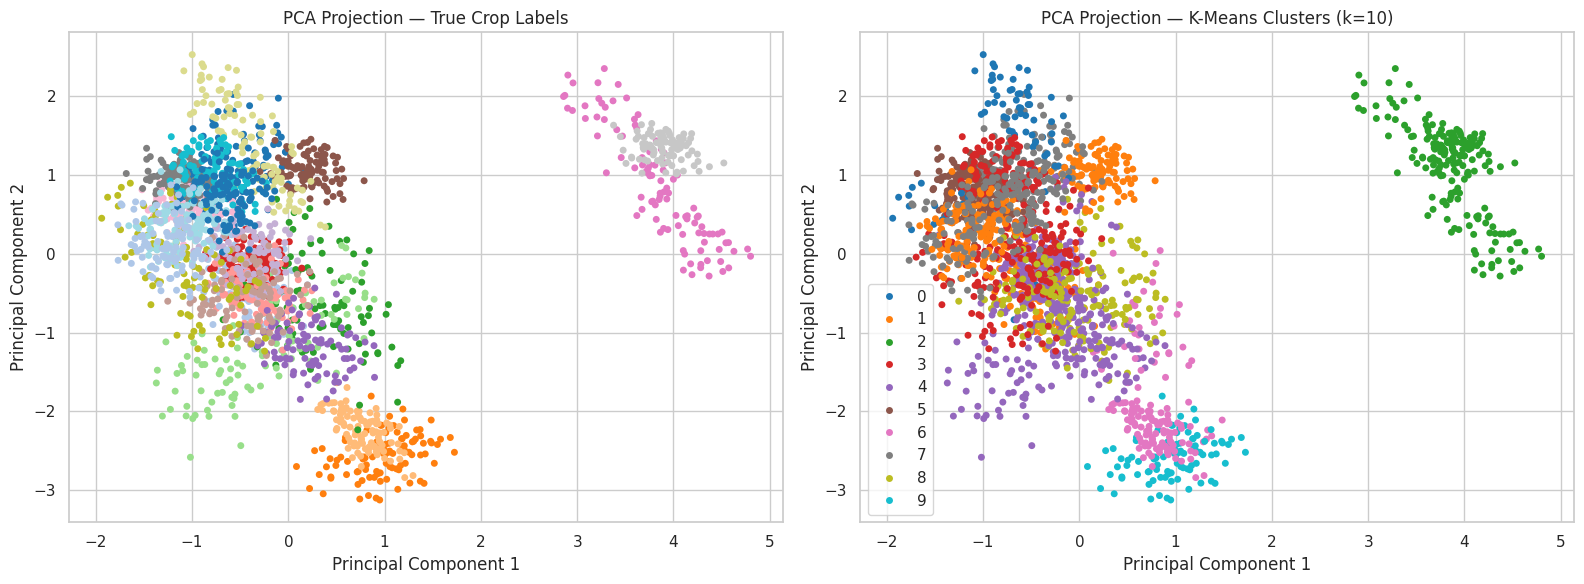

True crop,apple,banana,blackgram,chickpea,coconut,coffee,cotton,grapes,jute,kidneybeans,lentil,maize,mango,mothbeans,mungbean,muskmelon,orange,papaya,pigeonpeas,pomegranate,rice,watermelon
K-Means cluster,,,,,,,,,,,,,,,,,,,,,,
0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,18,58,3,0,0,0
1,0,100,0,0,0,28,100,0,0,0,0,99,0,0,0,0,0,8,0,0,0,0
2,100,0,0,0,0,0,0,100,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,100,0,0,0,0,0,0,0,0,0,0,0,80,3,0,100,0,0
4,0,0,100,0,0,0,0,0,0,0,96,1,11,58,100,0,2,13,9,0,0,0
5,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,100,0,0,0,0,0,100
6,0,0,0,5,0,0,0,0,0,100,4,0,0,0,0,0,0,0,32,0,0,0
7,0,0,0,0,0,72,0,0,100,0,0,0,0,0,0,0,0,18,1,0,100,0
8,0,0,0,0,0,0,0,0,0,0,0,0,89,42,0,0,0,0,55,0,0,0


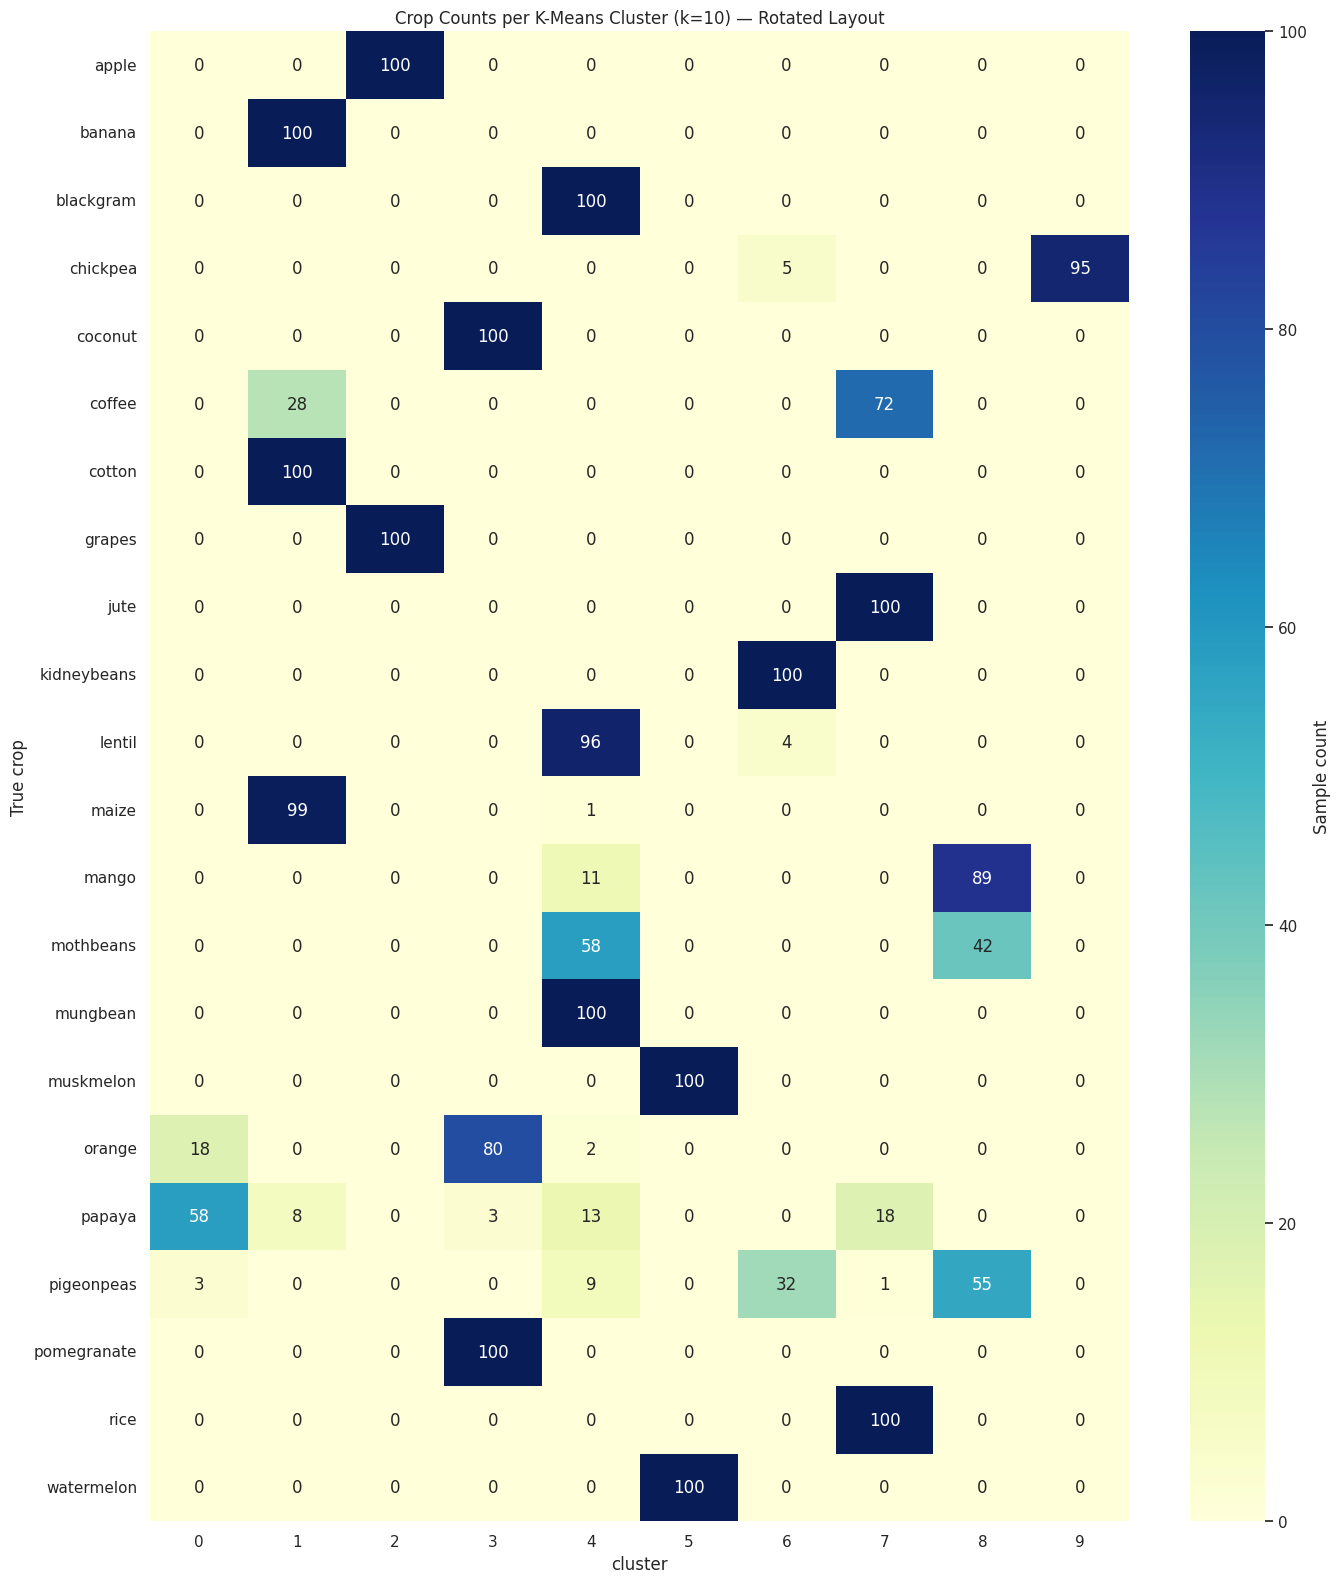

In [96]:
# Fit PCA on the standardized input features and transform to two dimensions.
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled_all)
print(f"Variance explained by first two components: {pca.explained_variance_ratio_.sum()*100:.2f}%")

# Plot true crop labels and unsupervised K-Means clusters side by side.
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=df[TARGET].astype(str),
                palette="tab20", s=25, linewidth=0, ax=axes[0], legend=False)
axes[0].set_title("PCA Projection — True Crop Labels")
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=kmeans10_labels,
                palette="tab10", s=25, linewidth=0, ax=axes[1], legend="brief")
axes[1].set_title("PCA Projection — K-Means Clusters (k=10)")
for ax in axes:
    ax.set_xlabel("Principal Component 1")
    ax.set_ylabel("Principal Component 2")
plt.tight_layout()
plt.show()

# Show the number of samples of each crop assigned to each K-Means cluster.
cluster_crop_table = pd.crosstab(
    pd.Series(kmeans10_labels, name="K-Means cluster"),
    pd.Series(df[TARGET].astype(str), name="True crop")
)
display(cluster_crop_table)

# Rotate the heatmap so True crop is vertical and K-Means is horizontal, displaying numbers in each block
plt.figure(figsize=(14, 16))
sns.heatmap(cluster_crop_table.T, cmap="YlGnBu", annot=True, fmt="d", cbar_kws={'label': 'Sample count'})
plt.title("Crop Counts per K-Means Cluster (k=10) — Rotated Layout")
plt.xlabel("cluster")
plt.ylabel("True crop")
plt.tight_layout()
plt.show()

## 14. Robustness evaluation with artificial Gaussian noise


In [97]:
logistic_pipeline = fitted_baselines["Logistic Regression"]

X_test_scaled = scaler.transform(X_test)
train_feature_std = np.std(
    scaler.transform(X_train),
    axis=0, ddof=0
)

noise_levels = [0.0, 0.1, 0.2, 0.3, 0.5]
noise_rows = []

for noise_level in noise_levels:
    rng = np.random.default_rng(RANDOM_STATE + int(noise_level * 1000))
    noise = rng.normal(
        loc=0.0,
        scale=noise_level * train_feature_std,
        size=X_test_scaled.shape
    )
    X_noisy_scaled = X_test_scaled + noise

    ensemble_noisy_proba = predict_ensemble_probabilities(X_noisy_scaled)
    ensemble_noisy_pred = np.argmax(ensemble_noisy_proba, axis=1)

    logistic_noisy_pred = logistic_pipeline.predict(X_noisy_scaled)

    noise_rows.append({
        "Noise (x feature std)": noise_level,
        "Ensemble Accuracy (%)": accuracy_score(y_test, ensemble_noisy_pred) * 100,
        "Logistic Regression Accuracy (%)": accuracy_score(y_test, logistic_noisy_pred) * 100
    })

noise_results = pd.DataFrame(noise_rows)
display(noise_results.round(2))

,Noise (x feature std),Ensemble Accuracy (%),Logistic Regression Accuracy (%)
0,0.0,99.55,97.27
1,0.1,97.73,96.14
2,0.2,91.82,93.18
3,0.3,81.36,87.05
4,0.5,61.36,66.82
